In [19]:
import glob
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [20]:
configs = {
    "fifo 20%":     ("fifo", 20, "../vspart/data/fifo_h20_*.csv"),
    "fifo 70%":     ("fifo", 70, "../vspart/data/fifo_h70_*.csv"),
    "priority 20%": ("priority", 20, "../vspart/data/priority_h20_*.csv"),
    "priority 70%": ("priority", 70, "../vspart/data/priority_h70_*.csv"),
}

frames = []
for name, (mode, share, pattern) in configs.items():
    df = pd.read_csv(sorted(glob.glob(pattern))[-1])
    df["mode"] = mode
    df["high_share"] = share
    frames.append(df)
runs = pd.concat(frames, ignore_index=True)

In [21]:
os.makedirs("../report", exist_ok=True)
sns.set_theme(style="whitegrid")

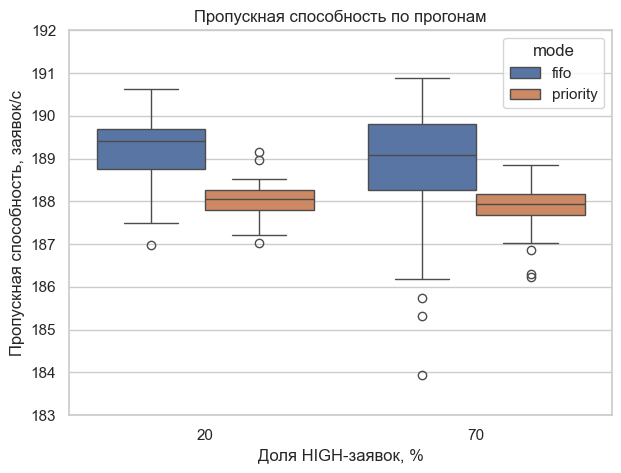

In [24]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=runs, x="high_share", y="throughput", hue="mode")
plt.xlabel("Доля HIGH-заявок, %")
plt.ylabel("Пропускная способность, заявок/с")
plt.title("Пропускная способность по прогонам")
plt.ylim(183, 192)
plt.savefig("../images/plot_throughput.png", dpi=200, bbox_inches="tight")

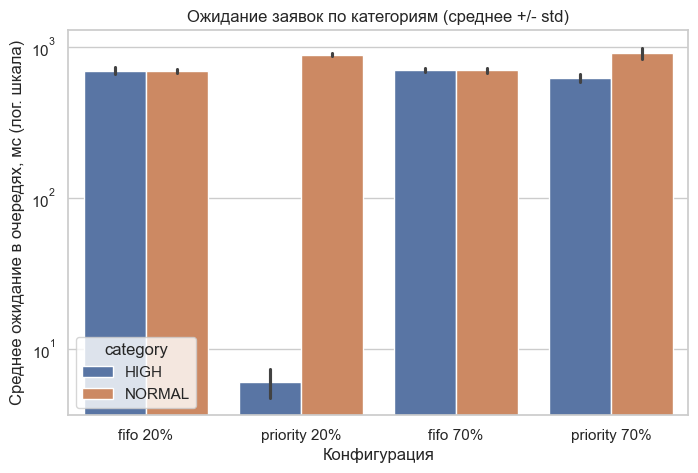

In [23]:
waits = runs.melt(
    id_vars=["mode", "high_share"],
    value_vars=["high_avg_wait", "normal_avg_wait"],
    var_name="category",
    value_name="wait",
)
waits["category"] = waits["category"].map({"high_avg_wait": "HIGH", "normal_avg_wait": "NORMAL"})
waits["config"] = waits["mode"] + " " + waits["high_share"].astype(str) + "%"

plt.figure(figsize=(8, 5))
sns.barplot(
    data=waits, x="config", y="wait", hue="category",
    order=["fifo 20%", "priority 20%", "fifo 70%", "priority 70%"],
    errorbar="sd",
)
plt.yscale("log")
plt.xlabel("Конфигурация")
plt.ylabel("Среднее ожидание в очередях, мс (лог. шкала)")
plt.title("Ожидание заявок по категориям (среднее +/- std)")
plt.savefig("../images/plot_wait.png", dpi=150, bbox_inches="tight")

plt.show()